You can order print and ebook versions of *Think Bayes 2e* from
[Bookshop.org](https://bookshop.org/a/98697/9781492089469) and
[Amazon](https://amzn.to/334eqGo).

# Grid algorithms for hierarchical models

Copyright 2021 Allen B. Downey

License: [Attribution-NonCommercial-ShareAlike 4.0 International (CC BY-NC-SA 4.0)](https://creativecommons.org/licenses/by-nc-sa/4.0/)

It is widely believed that grid algorithms are only practical for models with 1-3 parameters, or maybe 4-5 if you are careful.
[I've said so myself](https://allendowney.github.io/ThinkBayes2/chap19.html).

But recently I used a grid algorithm to solve the [emitter-detector problem](https://www.allendowney.com/blog/2021/09/05/emitter-detector-redux/), and along the way I noticed something about the structure of the problem: although the model has two parameters, the data only depend on one of them.
That makes it possible to evaluate the likelihood function and update the model very efficiently.

Many hierarchical models have a similar structure: the data depend on a small number of parameters, which depend on a small number of hyperparameters.
I wondered whether the same method would generalize to more complex models, and it does.

As an example, in this notebook I'll use a logitnormal-binomial hierarchical model to solve a problem with two hyperparameters and 13 parameters.
The grid algorithm is not just practical; it's substantially faster than MCMC.

In [1]:
# If we're running on Colab, install libraries
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    !pip install pymc3
    !pip install arviz
    !pip install empiricaldist

In [2]:
# PyMC generates a FutureWarning we don't need to deal with

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

The following are some utility functions I'll use.

In [3]:
import matplotlib.pyplot as plt

def legend(**options):
    """Make a legend only if there are labels."""
    handles, labels = plt.gca().get_legend_handles_labels()
    if len(labels):
        plt.legend(**options)

In [4]:
def decorate(**options):
    plt.gca().set(**options)
    legend()
    plt.tight_layout()

In [5]:
from empiricaldist import Cdf

def compare_cdf(pmf, sample):
    pmf.make_cdf().step(label='grid')
    Cdf.from_seq(sample).plot(label='mcmc')
    print(pmf.mean(), sample.mean())
    decorate()

In [6]:
from empiricaldist import Pmf

def make_pmf(ps, qs, name):
    pmf = Pmf(ps, qs)
    pmf.normalize()
    pmf.index.name = name
    return pmf

## Heart Attack Data

The problem I'll solve is based on [Chapter 10 of *Probability and Bayesian Modeling*](https://bayesball.github.io/BOOK/bayesian-hierarchical-modeling.html#example-deaths-after-heart-attack); it uses data on death rates due to heart attack for patients treated at various hospitals in New York City.

We can use Pandas to read the data into a `DataFrame`.

In [7]:
import os

filename = 'DeathHeartAttackManhattan.csv'
if not os.path.exists(filename):
    !wget https://github.com/AllenDowney/BayesianInferencePyMC/raw/main/DeathHeartAttackManhattan.csv

In [8]:
import pandas as pd

df = pd.read_csv(filename)
df

,Hospital,Cases,Deaths,Death %
0,Bellevue Hospital Center,129,4,3.101
1,Harlem Hospital Center,35,1,2.857
2,Lenox Hill Hospital,228,18,7.894
3,Metropolitan Hospital Center,84,7,8.333
4,Mount Sinai Beth Israel,291,24,8.247
5,Mount Sinai Hospital,270,16,5.926
6,Mount Sinai Roosevelt,46,6,13.043
7,Mount Sinai St. Luke’s,293,19,6.485
8,NYU Hospitals Center,241,15,6.224
9,NYP Hospital - Allen Hospital,105,13,12.381


The columns we need are `Cases`, which is the number of patients treated at each hospital, and `Deaths`, which is the number of those patients who died.

In [9]:
data_ns = df['Cases'].values
data_ks = df['Deaths'].values

## Solution with PyMC

Here's a hierarchical model that estimates the death rate for each hospital and simultaneously estimates the distribution of rates across hospitals.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
import pymc3 as pm

def make_model():
    with pm.Model() as model:
        mu = pm.Normal('mu', 0, 2)
        sigma = pm.HalfNormal('sigma', sigma=1)
        xs = pm.LogitNormal('xs', mu=mu, sigma=sigma, shape=len(data_ns))
        ks = pm.Binomial('ks', n=data_ns, p=xs, observed=data_ks)
    return model
```

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
%time model = make_model()
pm.model_to_graphviz(model)
```

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
with model:
    pred = pm.sample_prior_predictive(1000)
    %time trace = pm.sample(500, target_accept=0.97)
```

To be fair, PyMC doesn't like this parameterization much (although I'm not sure why). One most runs, there are a moderate number of divergences. Even so, the results are good enough. 

Here are the posterior distributions of the hyperparameters.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
import arviz as az

with model:
    az.plot_posterior(trace, var_names=['mu', 'sigma'])
```

And we can extract the posterior distributions of the xs.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
trace_xs = trace['xs'].transpose()
trace_xs.shape
```

As an example, here's the posterior distribution of x for the first hospital.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
with model:
    az.plot_posterior(trace_xs[0])
```

## The grid priors

Now let's solve the same problem using a grid algorithm.
I'll use the same priors for the hyperparameters, approximated by a grid with about 100 elements in each dimension.

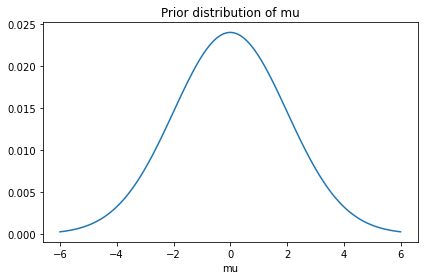

In [16]:
import numpy as np
from scipy.stats import norm

mus = np.linspace(-6, 6, 101)
ps = norm.pdf(mus, 0, 2)
prior_mu = make_pmf(ps, mus, 'mu')

prior_mu.plot()
decorate(title='Prior distribution of mu')

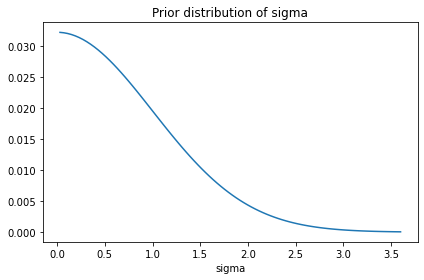

In [17]:
from scipy.stats import logistic

sigmas = np.linspace(0.03, 3.6, 90)
ps = norm.pdf(sigmas, 0, 1)
prior_sigma = make_pmf(ps, sigmas, 'sigma')

prior_sigma.plot()
decorate(title='Prior distribution of sigma')

The following cells confirm that these priors are consistent with the prior samples from PyMC.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
compare_cdf(prior_mu, pred['mu'])
decorate(title='Prior distribution of mu')
```

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
compare_cdf(prior_sigma, pred['sigma'])
decorate(title='Prior distribution of sigma')
```


## The joint distribution of hyperparameters

I'll use `make_joint` to make an array that represents the joint prior distribution of the hyperparameters.

In [20]:
def make_joint(prior_x, prior_y):
    X, Y = np.meshgrid(prior_x.ps, prior_y.ps, indexing='ij')
    hyper = X * Y
    return hyper

In [21]:
prior_hyper = make_joint(prior_mu, prior_sigma)
prior_hyper.shape

(101, 90)

Here's what it looks like.

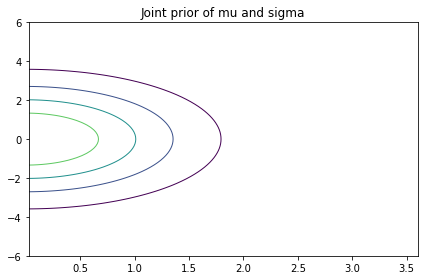

In [22]:
import pandas as pd
from utils import plot_contour

plot_contour(pd.DataFrame(prior_hyper, index=mus, columns=sigmas))
decorate(title="Joint prior of mu and sigma")

## Joint prior of hyperparameters and x

Now we're ready to lay out the grid for x, which is the proportion we'll estimate for each hospital.

In [23]:
xs = np.linspace(0.01, 0.99, 295)

For each pair of hyperparameters, we'll compute the distribution of `x`.

In [24]:
from scipy.special import logit

M, S, X = np.meshgrid(mus, sigmas, xs, indexing='ij')
LO = logit(X)
LO.sum()

-6.440927791118156e-10

In [25]:
from scipy.stats import norm

%time normpdf = norm.pdf(LO, M, S)
normpdf.sum()

CPU times: user 69.6 ms, sys: 16.5 ms, total: 86.1 ms
Wall time: 84.9 ms


214125.5678798693


We can speed this up by computing skipping the terms that don't depend on x

In [26]:
%%time

z = (LO-M) / S
normpdf = np.exp(-z**2/2)

CPU times: user 26 ms, sys: 10.6 ms, total: 36.6 ms
Wall time: 35.1 ms


The result is a 3-D array with axes for mu, sigma, and x.

Now we need to normalize each distribution of `x`.

In [27]:
totals = normpdf.sum(axis=2)
totals.shape

(101, 90)

To normalize, we have to use a safe version of `divide` where `0/0` is `0`.

In [28]:
def divide(x, y):
    out = np.zeros_like(x)
    return np.divide(x, y, out=out, where=(y!=0))    

In [29]:
shape = totals.shape + (1,)
normpdf = divide(normpdf, totals.reshape(shape))
normpdf.shape

(101, 90, 295)

The result is an array that contains the distribution of `x` for each pair of hyperparameters.

Now, to get the prior distribution, we multiply through by the joint distribution of the hyperparameters.

In [30]:
def make_prior(hyper):

    # reshape hyper so we can multiply along axis 0
    shape = hyper.shape + (1,)
    prior = normpdf * hyper.reshape(shape)

    return prior

In [31]:
%time prior = make_prior(prior_hyper)
prior.sum()

CPU times: user 5.57 ms, sys: 0 ns, total: 5.57 ms
Wall time: 4.87 ms


0.999937781278039

The result is a 3-D array that represents the joint prior distribution of `mu`, `sigma`, and `x`.

To check that it is correct, I'll extract the marginal distributions and compare them to the priors.

In [32]:
def marginal(joint, axis):
    axes = [i for i in range(3) if i != axis]
    return joint.sum(axis=tuple(axes))

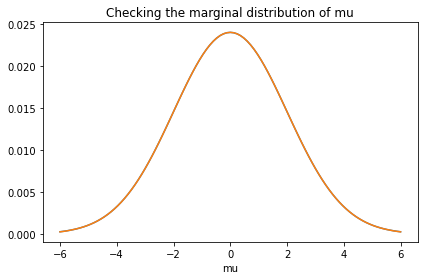

In [33]:
prior_mu.plot()
marginal_mu = Pmf(marginal(prior, 0), mus)
marginal_mu.plot()
decorate(title='Checking the marginal distribution of mu')

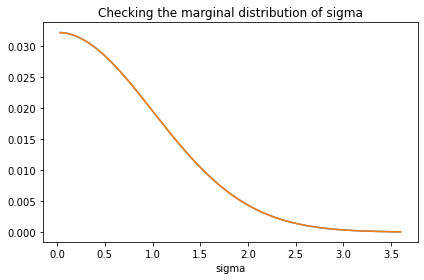

In [34]:
prior_sigma.plot()
marginal_sigma = Pmf(marginal(prior, 1), sigmas)
marginal_sigma.plot()
decorate(title='Checking the marginal distribution of sigma')

We didn't compute the prior distribution of `x` explicitly; it follows from the distribution of the hyperparameters. But we can extract the prior marginal of `x` from the joint prior.

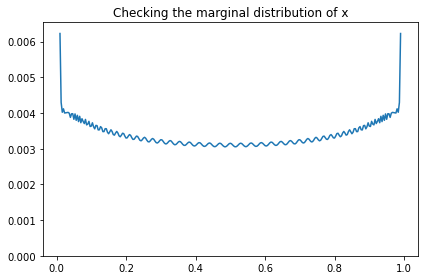

In [35]:
marginal_x = Pmf(marginal(prior, 2), xs)
marginal_x.plot()
decorate(title='Checking the marginal distribution of x',
         ylim=[0, np.max(marginal_x) * 1.05])

And compare it to the prior sample from PyMC.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
pred_xs = pred['xs'].transpose()
pred_xs.shape
```

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
compare_cdf(marginal_x, pred_xs[0])
decorate(title='Prior distribution of x')
```

The prior distribution of `x` I get from the grid is a bit different from what I get from PyMC. I'm not sure why, but it doesn't seem to affect the results much.

In addition to the marginals, we'll also find it useful to extract the joint marginal distribution of the hyperparameters.

In [38]:
def get_hyper(joint):
    return joint.sum(axis=2)

In [39]:
hyper = get_hyper(prior)

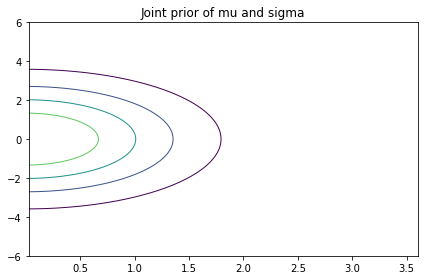

In [40]:
plot_contour(pd.DataFrame(hyper, 
                          index=mus, 
                          columns=sigmas))
decorate(title="Joint prior of mu and sigma")

## The Update

The likelihood of the data only depends on `x`, so we can compute it like this.

In [41]:
from scipy.stats import binom

data_k = data_ks[0]
data_n = data_ns[0]

like_x = binom.pmf(data_k, data_n, xs)
like_x.shape

(295,)

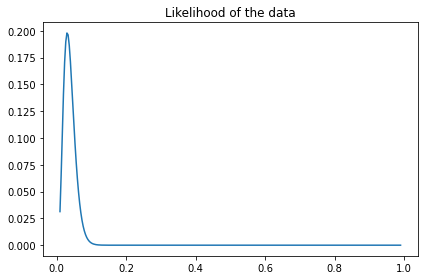

In [42]:
plt.plot(xs, like_x)
decorate(title='Likelihood of the data')

And here's the update.

In [43]:
def update(prior, data):
    n, k = data
    like_x = binom.pmf(k, n, xs)
    posterior = prior * like_x
    posterior /= posterior.sum()
    return posterior

In [44]:
data = data_n, data_k
%time posterior = update(prior, data)

CPU times: user 11.6 ms, sys: 11.9 ms, total: 23.5 ms
Wall time: 7.66 ms


## Serial updates

At this point we can do an update based on a single hospital, but how do we update based on all of the hospitals?

As a step toward the right answer, I'll start with a wrong answer, which is to do the updates one at a time.

After each update, we extract the posterior distribution of the hyperparameters and use it to create the prior for the next update.

At the end, the posterior distribution of hyperparameters is correct, and the marginal posterior of `x` for the *last* hospital is correct, but the other marginals are wrong because they do not take into account data from subsequent hospitals.

In [45]:
def multiple_updates(prior, ns, ks):
    for data in zip(ns, ks):
        print(data)
        posterior = update(prior, data)
        hyper = get_hyper(posterior)
        prior = make_prior(hyper)
    return posterior

In [46]:
%time posterior = multiple_updates(prior, data_ns, data_ks)

(129, 4)
(35, 1)
(228, 18)
(84, 7)
(291, 24)
(270, 16)
(46, 6)
(293, 19)
(241, 15)
(105, 13)
(353, 25)
(250, 11)
(41, 4)
CPU times: user 185 ms, sys: 35.4 ms, total: 220 ms
Wall time: 172 ms


Here are the posterior distributions of the hyperparameters, compared to the results from PyMC.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
marginal_mu = Pmf(marginal(posterior, 0), mus)
compare_cdf(marginal_mu, trace['mu'])
```

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
marginal_sigma = Pmf(marginal(posterior, 1), sigmas)
compare_cdf(marginal_sigma, trace['sigma'])
```

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
marginal_x = Pmf(marginal(posterior, 2), xs)
compare_cdf(marginal_x, trace_xs[-1])
```

## Parallel updates

Doing updates one at time is not quite right, but it gives us an insight.

Suppose we start with a uniform distribution for the hyperparameters and do an update with data from one hospital. If we extract the posterior joint distribution of the hyperparameters, what we get is the likelihood function associated with one dataset.

The following function computes these likelihood functions and saves them in an array called `hyper_likelihood`.

In [50]:
def compute_hyper_likelihood(ns, ks):
    shape = ns.shape + mus.shape + sigmas.shape
    hyper_likelihood = np.empty(shape)
    
    for i, data in enumerate(zip(ns, ks)):
        print(data)
        n, k = data
        like_x = binom.pmf(k, n, xs)
        posterior = normpdf * like_x
        hyper_likelihood[i] = get_hyper(posterior)
    return hyper_likelihood

In [51]:
%time hyper_likelihood = compute_hyper_likelihood(data_ns, data_ks)

(129, 4)
(35, 1)
(228, 18)
(84, 7)
(291, 24)
(270, 16)
(46, 6)
(293, 19)
(241, 15)
(105, 13)
(353, 25)
(250, 11)
(41, 4)
CPU times: user 82 ms, sys: 55.2 ms, total: 137 ms
Wall time: 75.5 ms


We can multiply this out to get the product of the likelihoods.

In [52]:
%time hyper_likelihood_all = hyper_likelihood.prod(axis=0)
hyper_likelihood_all.sum()

CPU times: user 279 µs, sys: 0 ns, total: 279 µs
Wall time: 158 µs


1.685854062633571e-14

This is useful because it provides an efficient way to compute the marginal posterior distribution of `x` for any hospital.
Here's an example.

In [53]:
i = 3
data = data_ns[i], data_ks[i]
data

(84, 7)

Suppose we did the updates serially and saved this hospital for last.
The prior distribution for the final update would reflect the updates from all previous hospitals, which we can compute by dividing out `hyper_likelihood[i]`.

In [54]:
%time hyper_i = divide(prior_hyper * hyper_likelihood_all, hyper_likelihood[i])
hyper_i.sum()

CPU times: user 310 µs, sys: 147 µs, total: 457 µs
Wall time: 342 µs


4.3344287278716945e-17

We can use `hyper_i` to make the prior for the last update.

In [55]:
prior_i = make_prior(hyper_i) 

And then do the update.

In [56]:
posterior_i = update(prior_i, data)

And we can confirm that the results are similar to the results from PyMC.

In [57]:
marginal_mu = Pmf(marginal(posterior_i, 0), mus)
marginal_sigma = Pmf(marginal(posterior_i, 1), sigmas)
marginal_x = Pmf(marginal(posterior_i, 2), xs)

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
compare_cdf(marginal_mu, trace['mu'])
```

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
compare_cdf(marginal_sigma, trace['sigma'])
```

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
compare_cdf(marginal_x, trace_xs[i])
```

## Compute all marginals

The following function computes the marginals for all hospitals and stores the results in an array.

In [61]:
def compute_all_marginals(ns, ks):
    shape = len(ns), len(xs)
    marginal_xs = np.zeros(shape)
    numerator = prior_hyper * hyper_likelihood_all
    
    for i, data in enumerate(zip(ns, ks)):
        hyper_i = divide(numerator, hyper_likelihood[i])
        prior_i = make_prior(hyper_i) 
        posterior_i = update(prior_i, data)
        marginal_xs[i] = marginal(posterior_i, 2)
        
    return marginal_xs

In [62]:
%time marginal_xs = compute_all_marginals(data_ns, data_ks)

CPU times: user 184 ms, sys: 49.8 ms, total: 234 ms
Wall time: 173 ms


Here's what the results look like, compared to the results from PyMC.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
for i, ps in enumerate(marginal_xs):
    pmf = Pmf(ps, xs)
    plt.figure()
    compare_cdf(pmf, trace_xs[i])
    decorate(title=f'Posterior marginal of x for Hospital {i}',
             xlabel='Death rate',
             ylabel='CDF',
             xlim=[trace_xs[i].min(), trace_xs[i].max()])
```

And here are the percentage differences between the results from the grid algorithm and PyMC. Most of them are less than 1%.

> **ALPS compatibility:** This optional comparison uses the legacy PyMC3 stack, which is not available in the ALPS browser runtime. The grid-based analysis in this notebook remains executable.

The original textbook code is preserved for reference:

```python
for i, ps in enumerate(marginal_xs):
    pmf = Pmf(ps, xs)
    diff = abs(pmf.mean() - trace_xs[i].mean()) / pmf.mean()
    print(diff * 100)
```

The total time to do all of these computations is about 300 ms, compared to more than 10 seconds to make and run the PyMC model. And PyMC used 4 cores; I only used one.

The grid algorithm is easy to parallelize, and it's incremental. If you get data from a new hospital, or new data for an existing one, you can:

1) Compute the posterior distribution of `x` for the updated hospital, using existing `hyper_likelihoods` for the other hospitals.

2) Update `hyper_likelihoods` for the other hospitals, and run their updates again.

The total time would be about half of what it takes to start from scratch, and it's easy to parallelize.

One drawback of the grid algorithm is that it generates marginal distributions for each hospital rather than a sample from the joint distribution of all of them. So it's less easy to see the correlations among them.

The other drawback, in general, is that it takes more work to set up the grid algorithm. If we switch to another parameterization, it's easier to change the PyMC model.